# Aulas IA Preditiva Modulo1 Semana 11 Aula2 e Aula3

### Pipeline do Caso: Airbnb

In [5]:
import pandas as pd

pd.set_option('display.width', 110)
pd.set_option('display.max_columns', 10)

bruto = pd.read_csv('dados/brutos/airbnb_rio_bruto.csv')
print(bruto.shape)
bruto[['name', 'host_name', 'neighbourhood_cleansed', 'price', 'minimum_nights', 'last_review']].head(3)



(3060, 25)


,name,host_name,neighbourhood_cleansed,price,minimum_nights,last_review
0,Vaga para mulheres,Anfitrião 1430,Barra da Tijuca,$68.00,1.0,NaN
1,Beautiful apartment on Ipanema beach,Anfitrião 984,Ipanema,"$1,527.50",1.0,2026-09-10
2,Loft em localização na cidade maravilhosa !,Anfitrião 586,Flamengo,$224.00,5.0,2026-05-05


            média  mediana
price  803.333973   446.67


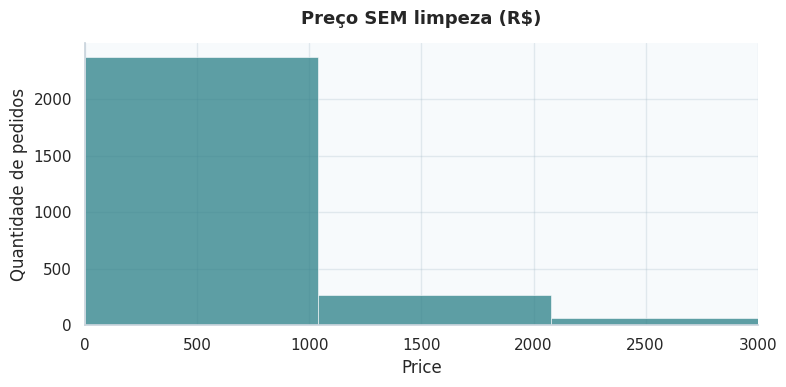

In [6]:
from pipeline_limpeza import Analise, Graficos

sem_limpar = bruto.copy()
sem_limpar['price'] = pd.to_numeric(sem_limpar['price'].str.replace(r'[$,]', '', regex=True), errors='coerce')
print(Analise(sem_limpar).tabela_media_mediana('price'))
Graficos(sem_limpar).histograma('price', 'Preço SEM limpeza (R$)', bins=40, limite=(0, 3000))


In [7]:
from pipeline_limpeza import PipelineLimpeza

pipeline = PipelineLimpeza()
limpo = pipeline.limpar(bruto)
print('linhas:', len(bruto), '->', len(limpo), '| colunas:', limpo.shape[1])


INFO | TratadorAusentes | várias: troquei 0 textos por NaN (linhas removidas: 0)
INFO | TratadorAusentes | neighbourhood_group_cleansed: removi a coluna (linhas removidas: 0)
INFO | TratadorAusentes | host_response_rate: removi a coluna (linhas removidas: 0)
INFO | TratadorAusentes | instant_bookable: removi a coluna (linhas removidas: 0)
INFO | TratadorTipos | price: converti para número (0 valores não convertidos viraram NaN) (linhas removidas: 0)
INFO | TratadorTexto | name: removi espaços extras (linhas removidas: 0)
INFO | TratadorTexto | host_name: removi espaços extras (linhas removidas: 0)


INFO | TratadorTipos | last_review: converti para datetime (errors='coerce') (linhas removidas: 0)
INFO | TratadorUnidades | bathrooms_text: criei 'banheiros' e 'banheiro_compartilhado' (linhas removidas: 0)
INFO | TratadorDuplicados | linha inteira: mantive a primeira ocorrência (linhas removidas: 60)
INFO | TratadorConsistencia | price: 15 valores inválidos viraram NaN (linhas removidas: 0)
INFO | TratadorOutliers | price: limitei 243 valores aos limites (linhas removidas: 0)
INFO | linhas: 3060 -> 3000


linhas: 3060 -> 3000 | colunas: 24


            média  mediana
price  570.658461   447.33


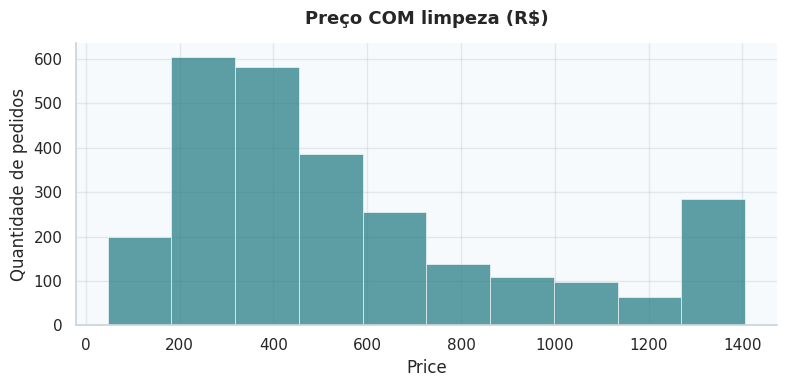

In [8]:
print(Analise(limpo).tabela_media_mediana('price'))
Graficos(limpo).histograma('price', 'Preço COM limpeza (R$)', bins=10)


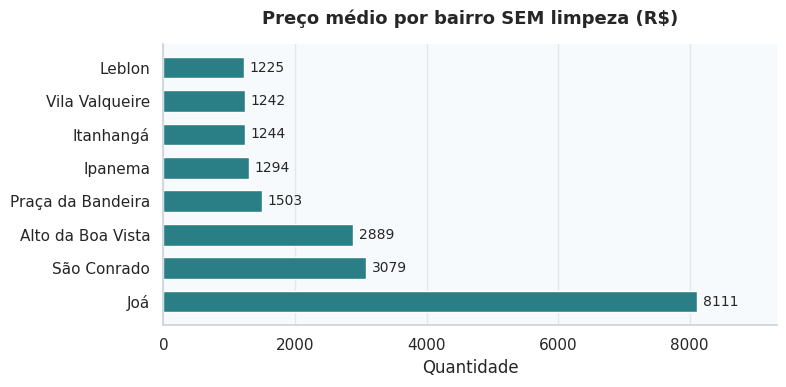

In [9]:
antes_bairro = sem_limpar.groupby('neighbourhood_cleansed')['price'].mean().nlargest(8)
Graficos(sem_limpar).barras_serie(antes_bairro, 'Preço médio por bairro SEM limpeza (R$)', fmt='%.0f', horizontal=True)


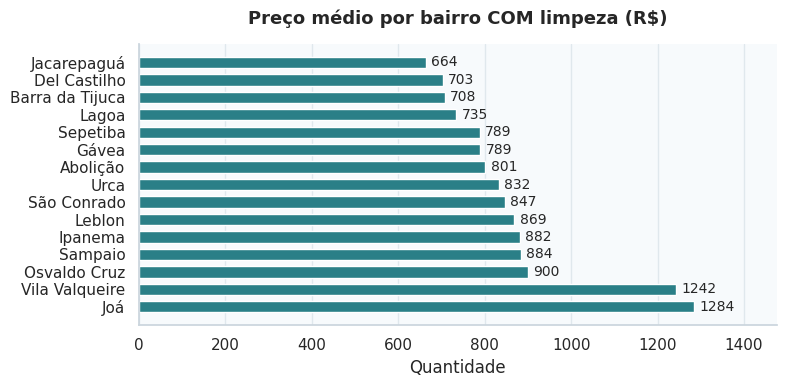

In [10]:
limpos_antes_bairro = limpo.groupby('neighbourhood_cleansed')['price'].mean().nlargest(15)
Graficos(sem_limpar).barras_serie(limpos_antes_bairro, 'Preço médio por bairro COM limpeza (R$)', fmt='%.0f', horizontal=True)

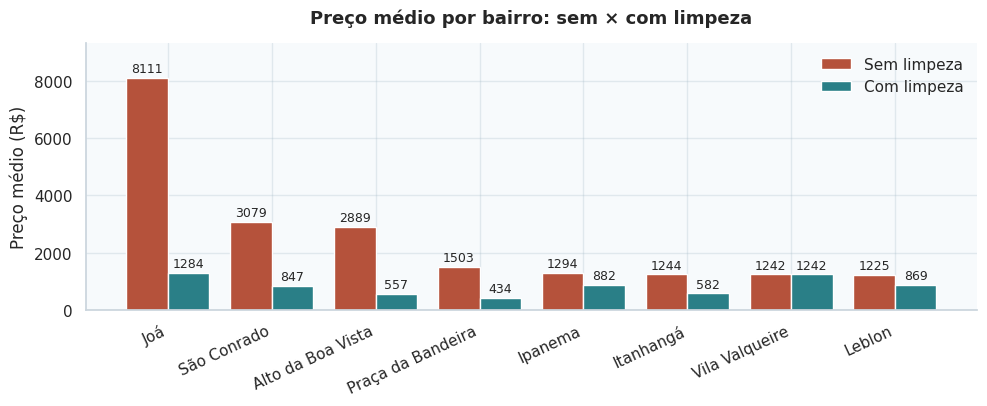

In [11]:
depois_bairro = limpo.groupby('neighbourhood_cleansed')['price'].mean().reindex(antes_bairro.index)
Graficos(limpo).comparar_barras(antes_bairro, depois_bairro, 'Preço médio por bairro: sem × com limpeza', fmt='%.0f')

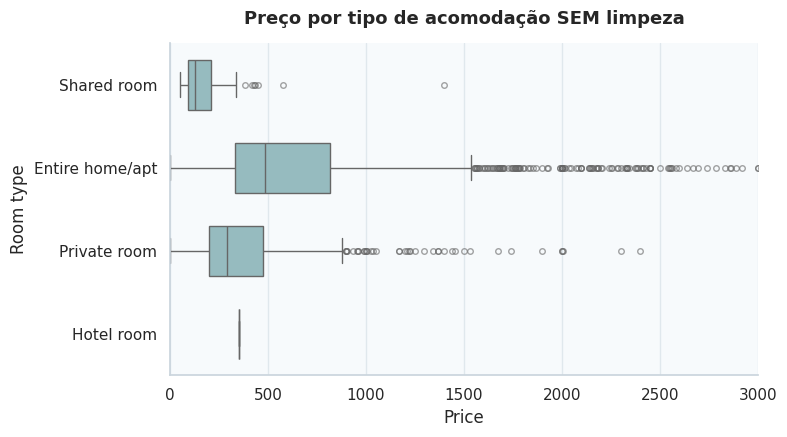

In [12]:
Graficos(sem_limpar).boxplot('price', 'Preço por tipo de acomodação SEM limpeza', grupo='room_type', limite=(0, 3000))


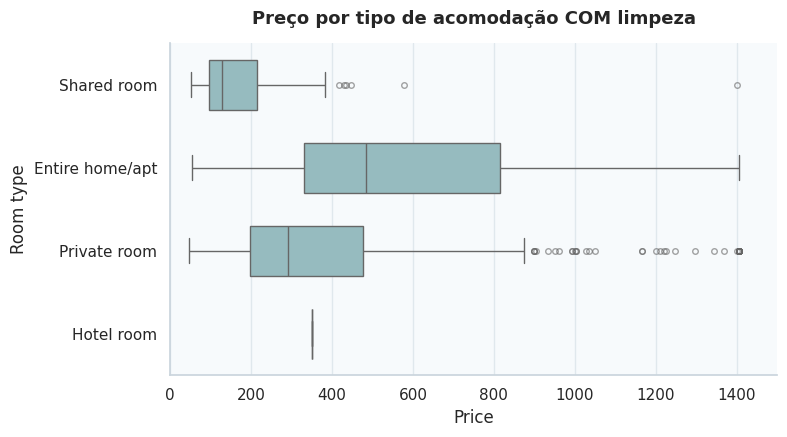

In [13]:
Graficos(limpo).boxplot('price', 'Preço por tipo de acomodação COM limpeza', grupo='room_type', limite=(0, 1500))

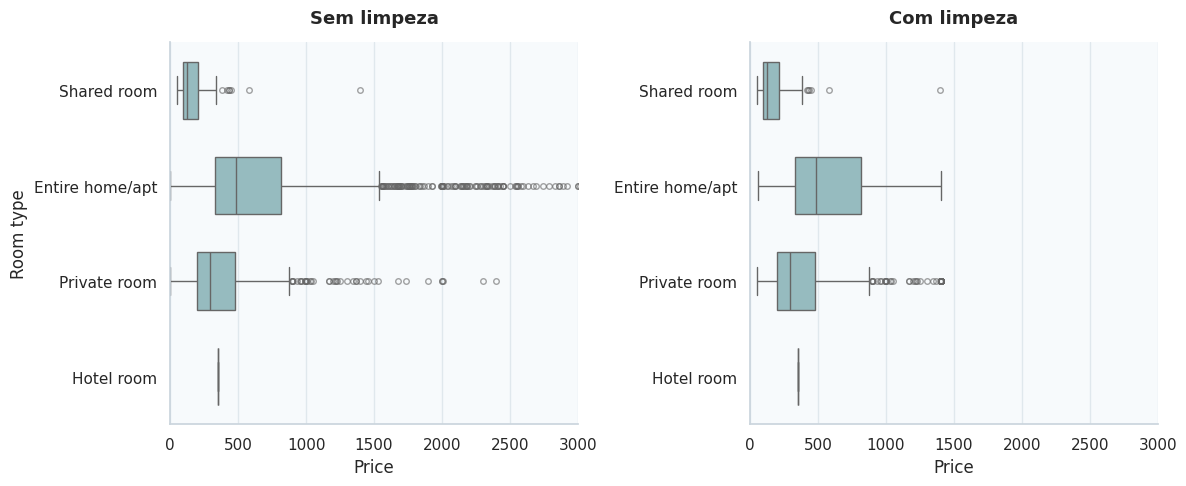

In [14]:
Graficos(limpo).comparar_boxplots(sem_limpar, limpo, 'price', grupo='room_type', limite=(0, 3000))


In [21]:
print("bruto['last_review'] tipo:", bruto['last_review'].dtypes)

try:
    dias_sem_limpar = pd.Timestamp('2026-09-30') - bruto['last_review']
except TypeError as erro:
    print('Não dá para calcular os dias:', erro)#type(erro).__name__)


bruto['last_review'] tipo: object
Não dá para calcular os dias: unsupported operand type(s) for -: 'Timestamp' and 'float'


datetime64[ns]


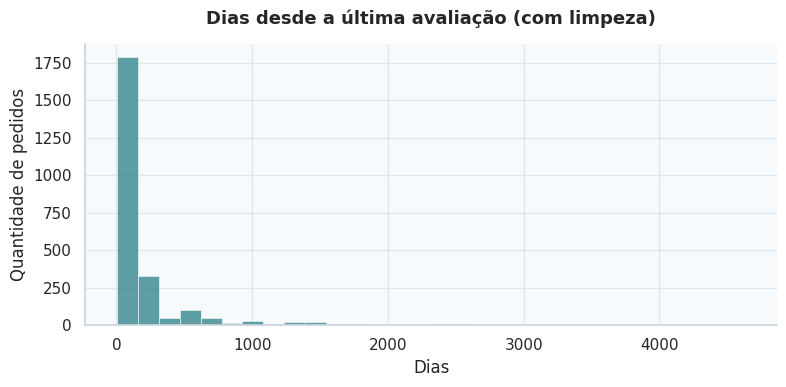

In [23]:
print(limpo['last_review'].dtype)

dias = (pd.Timestamp('2026-09-30') - limpo['last_review']).dt.days.dropna()
Graficos(limpo.assign(dias=dias)).histograma('dias', 'Dias desde a última avaliação (com limpeza)', bins=30)


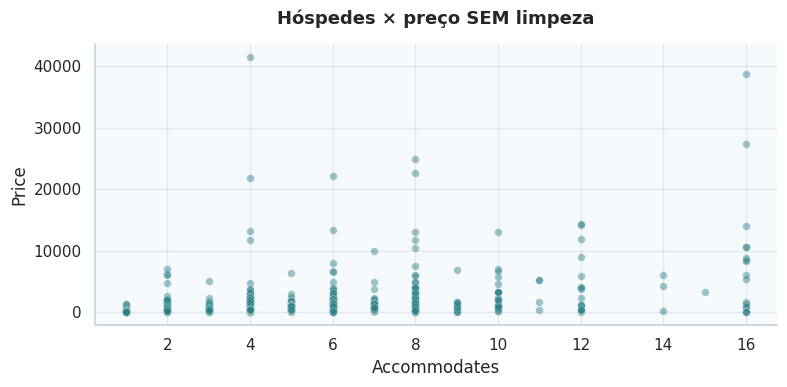

In [24]:
Graficos(sem_limpar).dispersao('accommodates', 'price', 'Hóspedes × preço SEM limpeza')

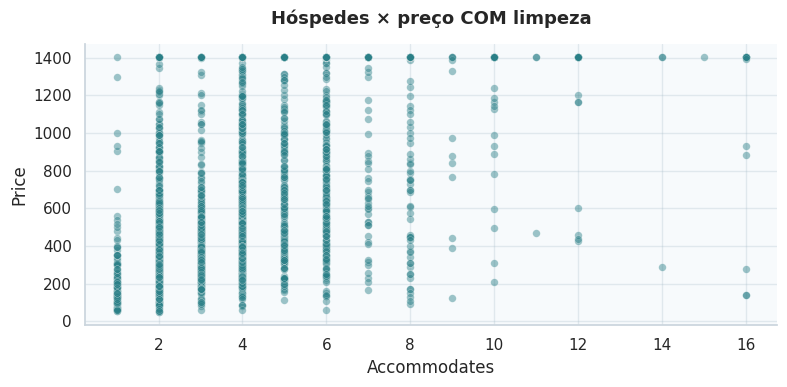

In [25]:
Graficos(limpo).dispersao('accommodates', 'price', 'Hóspedes × preço COM limpeza')


In [26]:
from casos.airbnb.analises import AnalisesAirbnb

analise = AnalisesAirbnb(limpo, minimo_imoveis=10)
mais_cara, mais_barata, tabela = analise.localidades_extremas()
print('Mais cara:', mais_cara, '| mais barata:', mais_barata)
print(tabela.head(3))


Mais cara: Joá | mais barata: Centro
                        imoveis    media  mediana
neighbourhood_cleansed                           
Joá                          12  1283.65  1405.82
Ipanema                     226   881.61   891.12
Leblon                      117   868.87    805.0


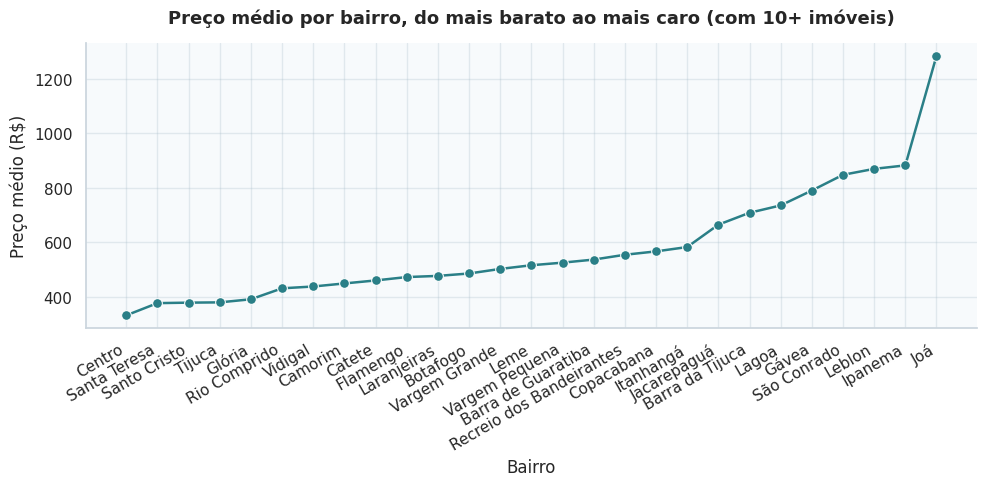

In [27]:
analise.linha_localidades()


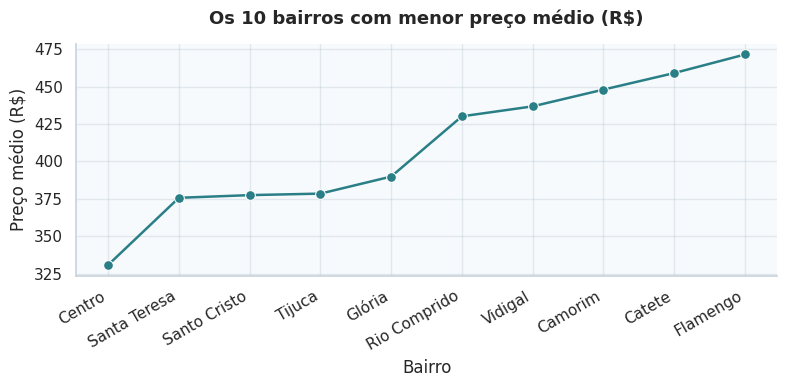

In [29]:
analise.linha_top_bairros(n=10, mais_caros=False)


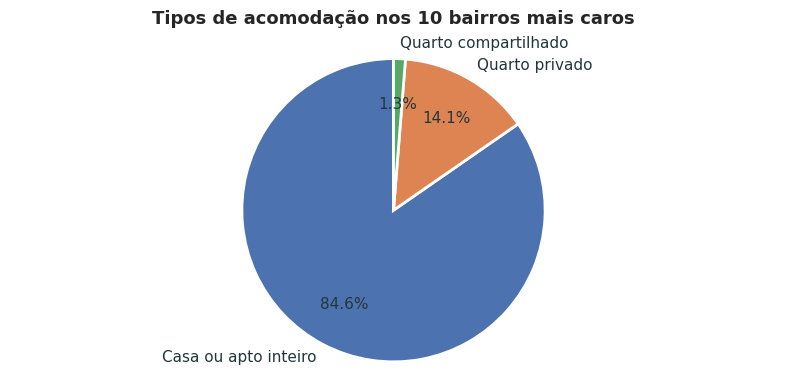

In [31]:
analise.pizza_tipos_nos_bairros(n=10, mais_caros=True)

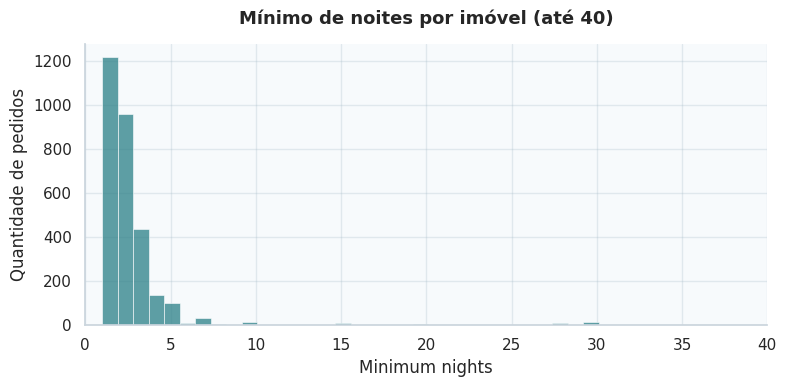

In [32]:
Graficos(limpo).histograma('minimum_nights', 'Mínimo de noites por imóvel (até 40)', bins=400, limite=(0, 40))

In [35]:
from pipeline_limpeza import LeitorDados

calendario = LeitorDados().ler('dados/brutos/calendario_airbnb_rio_amostra.csv.gz')
print('Noites no calendário:', len(calendario), '| colunas:', list(calendario.columns))


INFO | lido dados/brutos/calendario_airbnb_rio_amostra.csv.gz: 1095000 linhas, 5 colunas


Noites no calendário: 1095000 | colunas: ['listing_id', 'date', 'available', 'minimum_nights', 'maximum_nights']


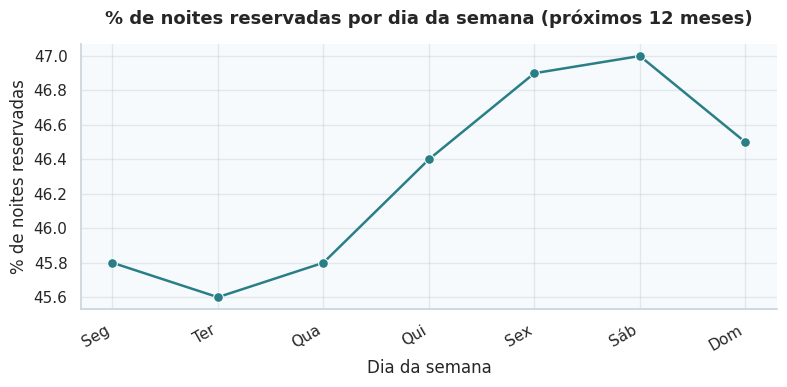

Seg    45.8
Ter    45.6
Qua    45.8
Qui    46.4
Sex    46.9
Sáb    47.0
Dom    46.5
Name: reservada, dtype: float64


In [36]:
analise.linha_dias_reservados(calendario)
print(analise.dias_reservados(calendario))


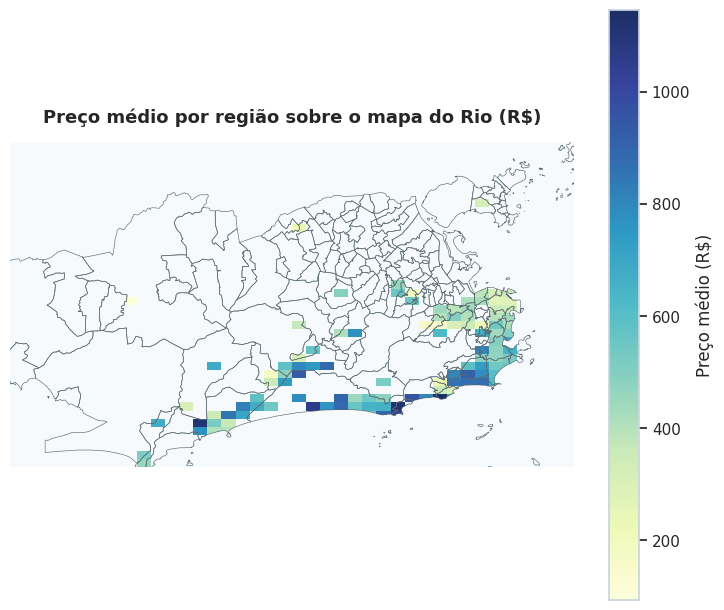

In [ ]:
analise.mapa_calor_sobre_mapa(faixas=40)

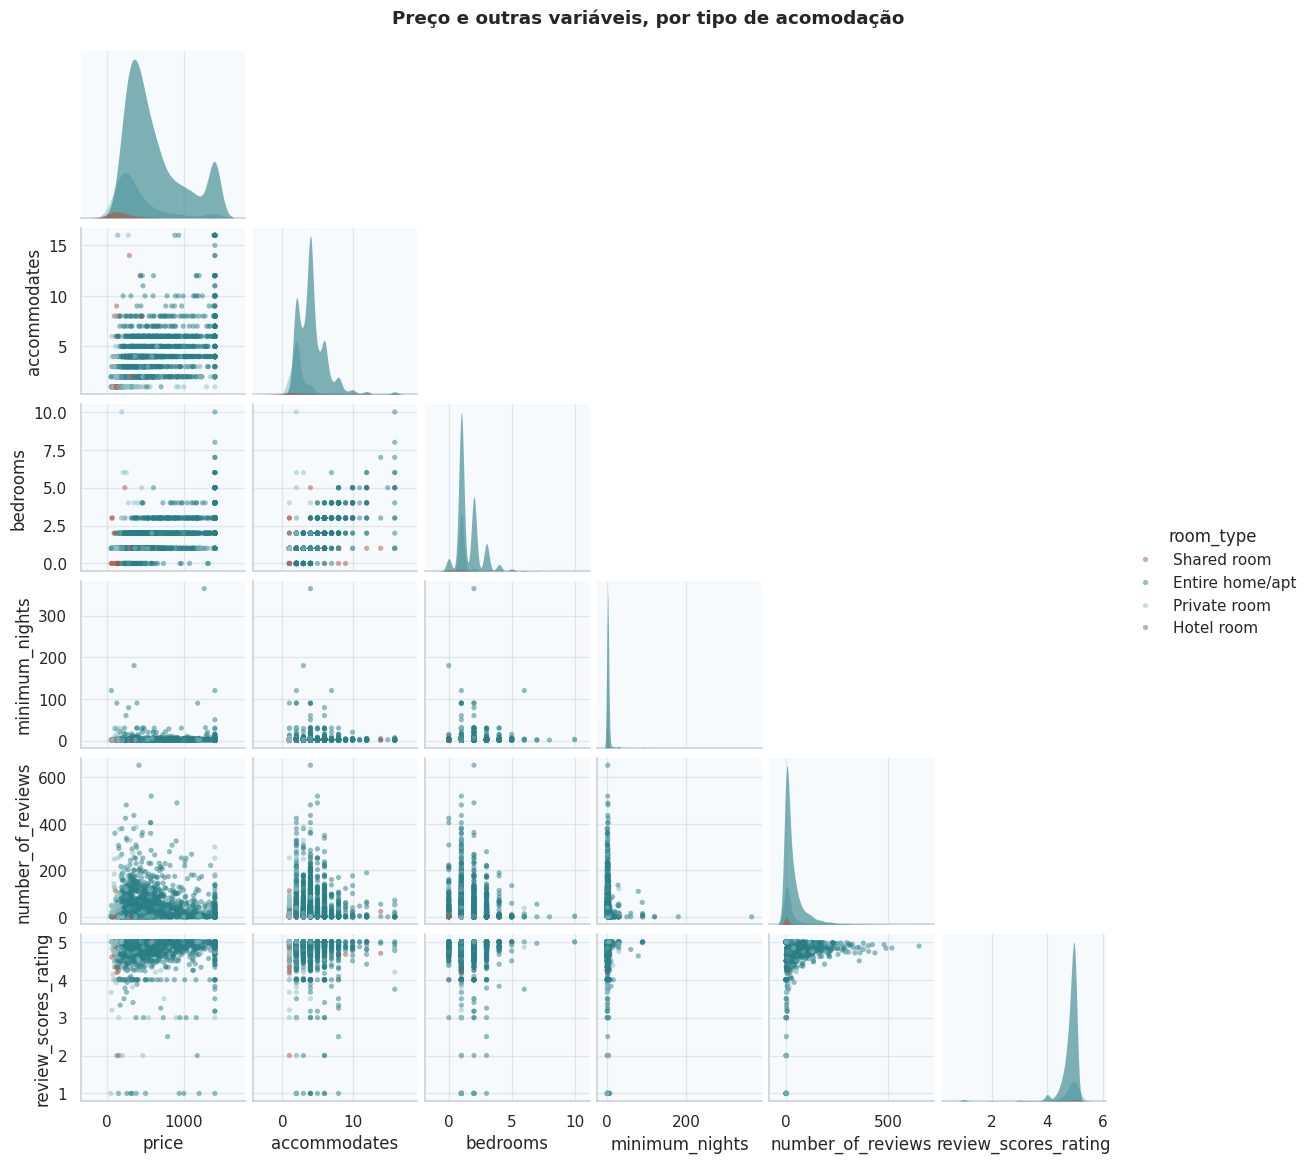

In [39]:
analise.matriz_variaveis()

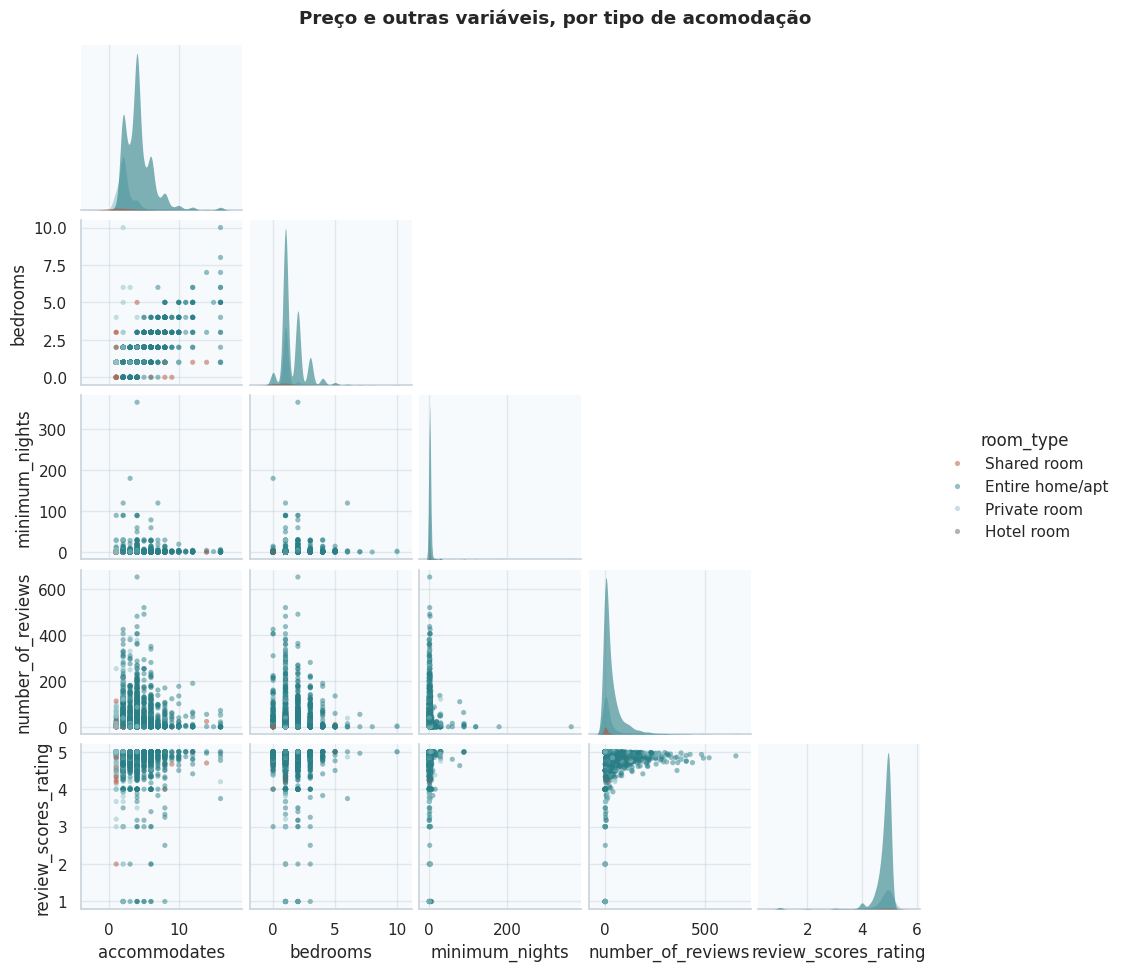

In [40]:
analise_sujo= AnalisesAirbnb(bruto, minimo_imoveis=10)
analise_sujo.matriz_variaveis()

In [41]:
from pipeline_limpeza import ExportadorDados
from pipeline_limpeza.config import SAIDAS_ANALISES

exportador = ExportadorDados(SAIDAS_ANALISES)
resumo = analise.precos_por_localidade().reset_index()
caminho = exportador.exportar(resumo, 'resumo_bairros.json')
print('Exportado:', caminho, '| bairros:', len(resumo))


INFO | exportado saidas/analises/resumo_bairros.json: 27 linhas


Exportado: saidas/analises/resumo_bairros.json | bairros: 27
